<a href="https://colab.research.google.com/github/sebassanchez5680-tech/Prueba/blob/main/271757_Data_Leakage_(Pipeline)_y_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

La presente tarea tiene como objetivo aplicar técnicas de aprendizaje automático para el tratamiento de clases no balanceadas utilizando un problema de clasificación real.

Para el desarrollo de la actividad deberán utilizar el conjunto de datos:

compustat.csv

Consideraciones importantes:

El conjunto de datos contiene 21 atributos.

El primer atributo corresponde a un índice, por lo que deberá ser ignorado durante el análisis y entrenamiento.

El último atributo corresponde a la etiqueta de clase.

Los atributos restantes deberán utilizarse como variables predictoras.

La solución deberá desarrollarse en un cuaderno de Google Colab o Jupyter Notebook almacenado en GitHub. La entrega consistirá en compartir la liga pública del notebook para su revisión.

La tarea deberá contener las siguientes secciones:

##1. Análisis Exploratorio de Datos (AED) - Para esta actividad revisa el Notebook que està en Teams en la Sesión 27 y que se llama DataLeakage_ClassImbalance.ipynb

Realizar:

Un diagrama de barras mostrando la distribución de las clases.

Diagramas de densidad KDE para los atributos 5 y 13.

Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.

/tmp/ipykernel_18944/2534709510.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y, palette="viridis") #diagrama de barras


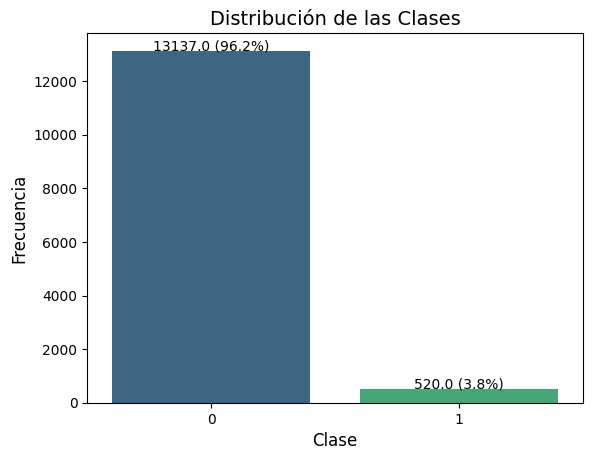

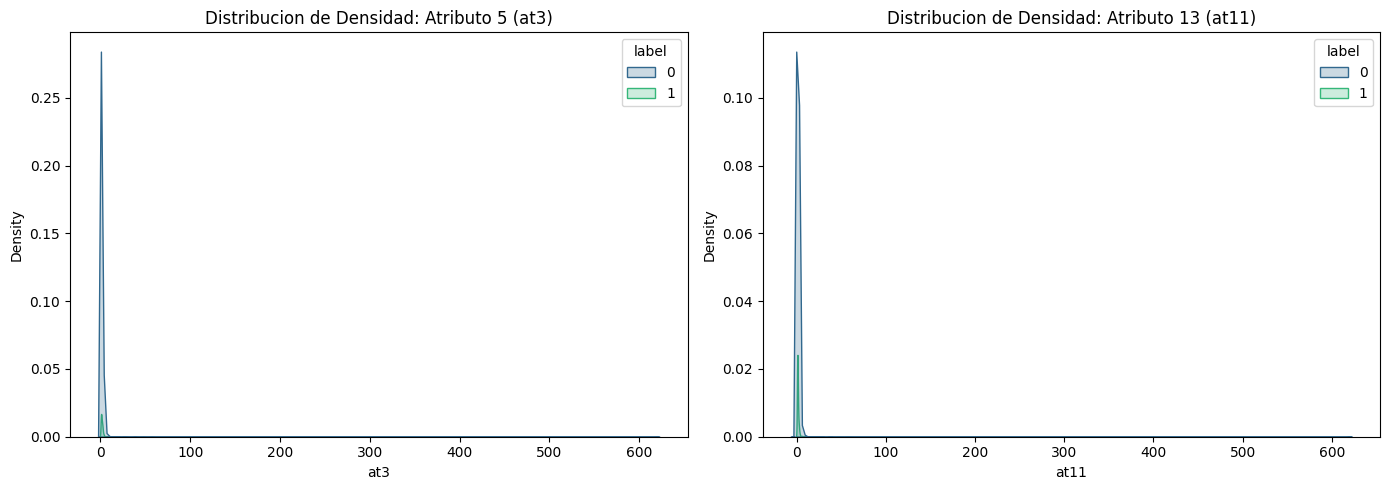

In [3]:
#!pip install imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection

df = pd.read_csv('compustat.csv')
df = df.iloc[:, 1:] #ignorando el indice

X = df.iloc[:, :-1]# Separar atributos predictivos
y = df.iloc[:, -1]

ax = sns.countplot(x=y, palette="viridis") #diagrama de barras
plt.title('Distribución de las Clases', fontsize=14)
plt.xlabel('Clase', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

total = len(y)
for p in ax.patches: #porcentaje de las barras
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 5,f'{height} ({(height/total)*100:.1f}%)',ha="center", fontsize=10)
plt.show()

attr_5 = X.columns[3]
attr_13 = X.columns[11]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df, x=attr_5, hue=y.name, fill=True, palette="viridis", ax=axes[0])
axes[0].set_title(f'Distribucion de Densidad: Atributo 5 ({attr_5})')
sns.kdeplot(data=df, x=attr_13, hue=y.name, fill=True, palette="viridis", ax=axes[1])
axes[1].set_title(f'Distribucion de Densidad: Atributo 13 ({attr_13})')
plt.tight_layout()
plt.show()

En el grafico de barras, el conjunto de datos presenta un desbalance muy marcado, donde se ve que una clase domina abrumadoramente sobre la otra. Este desbalance puede causar que el modelo de clasificación (en este caso, SVM) se sesgue hacia la clase mayoritaria, ignorando casi por completo los patrones de la clase minoritaria.

##2. Modelo Base

Entrenar un modelo baseline utilizando:

Pipeline([('scaler', StandardScaler()),('svm', SVC(kernel='rbf', C=10, gamma='scale'))])

Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.

##3. Tratamiento de Clases No Balanceadas

Aplicar y comparar los siguientes métodos:

SMOTEENN

One-Sided Selection

Para cada método:

Mostrar la nueva distribución de clases después del balanceo.

Entrenar nuevamente el modelo SVM utilizando los datos balanceados.



/tmp/ipykernel_18944/367224298.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, ax=axes[0], palette="viridis")
/tmp/ipykernel_18944/367224298.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_sm, ax=axes[1], palette="viridis") #smoteen
/tmp/ipykernel_18944/367224298.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_oss, ax=axes[2], palette="viridis") #one-sided


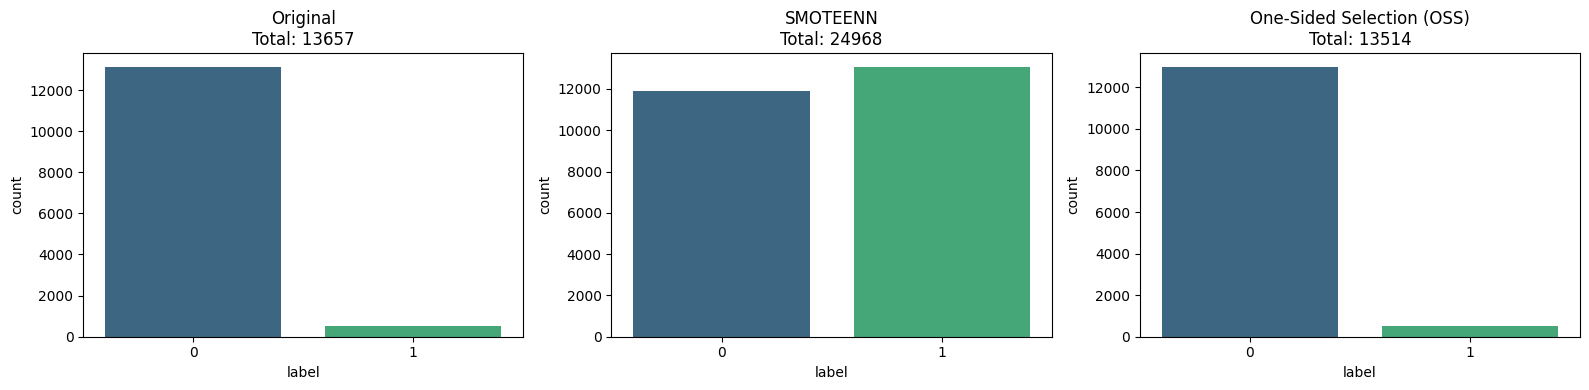

In [4]:
# 2. Modelo Base (Pipeline)
baseline_pipeline = ImbPipeline([('scaler', StandardScaler()),('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))])

# 3. Tratamiento de clases no balanceadas Pipelines para SMOTEENN y One-Sided Selection

smoteenn_pipeline = ImbPipeline([('sampler', SMOTEENN(random_state=42)),('scaler', StandardScaler()),
('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))])

oss_pipeline = ImbPipeline([
    ('sampler', OneSidedSelection(random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))])

smoteenn = SMOTEENN(random_state=42)
X_sm, y_sm = smoteenn.fit_resample(X, y)
oss = OneSidedSelection(random_state=42)
X_oss, y_oss = oss.fit_resample(X, y)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x=y, ax=axes[0], palette="viridis")
axes[0].set_title(f'Original\nTotal: {len(y)}') #original

sns.countplot(x=y_sm, ax=axes[1], palette="viridis") #smoteen
axes[1].set_title(f'SMOTEENN\nTotal: {len(y_sm)}')

sns.countplot(x=y_oss, ax=axes[2], palette="viridis") #one-sided
axes[2].set_title(f'One-Sided Selection (OSS)\nTotal: {len(y_oss)}')
plt.tight_layout()
plt.show()

## 4. Entrenamiento y Evaluación del Modelo
Utilizar validación cruzada estratificada de 5 particiones.

Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage.

Incorporar escalado de datos dentro del Pipeline.

Utilizar SVM con kernel RBF.
##5.Evaluación de Resultados
Reportar y analizar al menos las siguientes métricas:

Accuracy

Precision

Recall

F1-score

Matriz de confusión
Además:

Comparar los resultados del modelo baseline contra los modelos balanceados.

Generar una gráfica comparativa de métricas.

Analizar si Accuracy es suficiente para evaluar el problema.


Entrenando y evaluando: Baseline...
Entrenando y evaluando: SMOTEENN...
Entrenando y evaluando: One-Sided Selection...


,Modelo,Accuracy,Precision,Recall,F1-Score
0,Baseline,0.962217,0.981103,0.503846,0.498003
1,SMOTEENN,0.811965,0.567735,0.808066,0.569095
2,One-Sided Selection,0.962217,0.981103,0.503846,0.498003


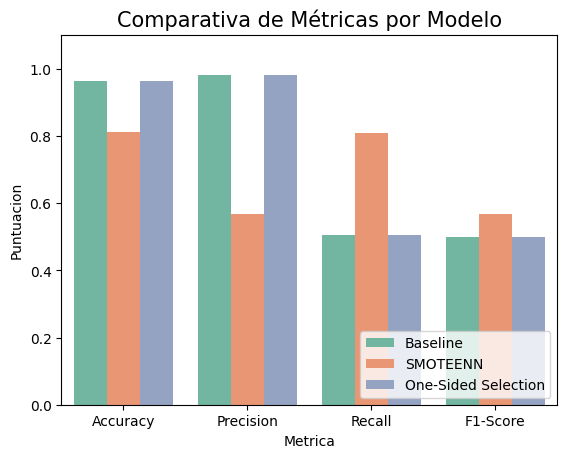

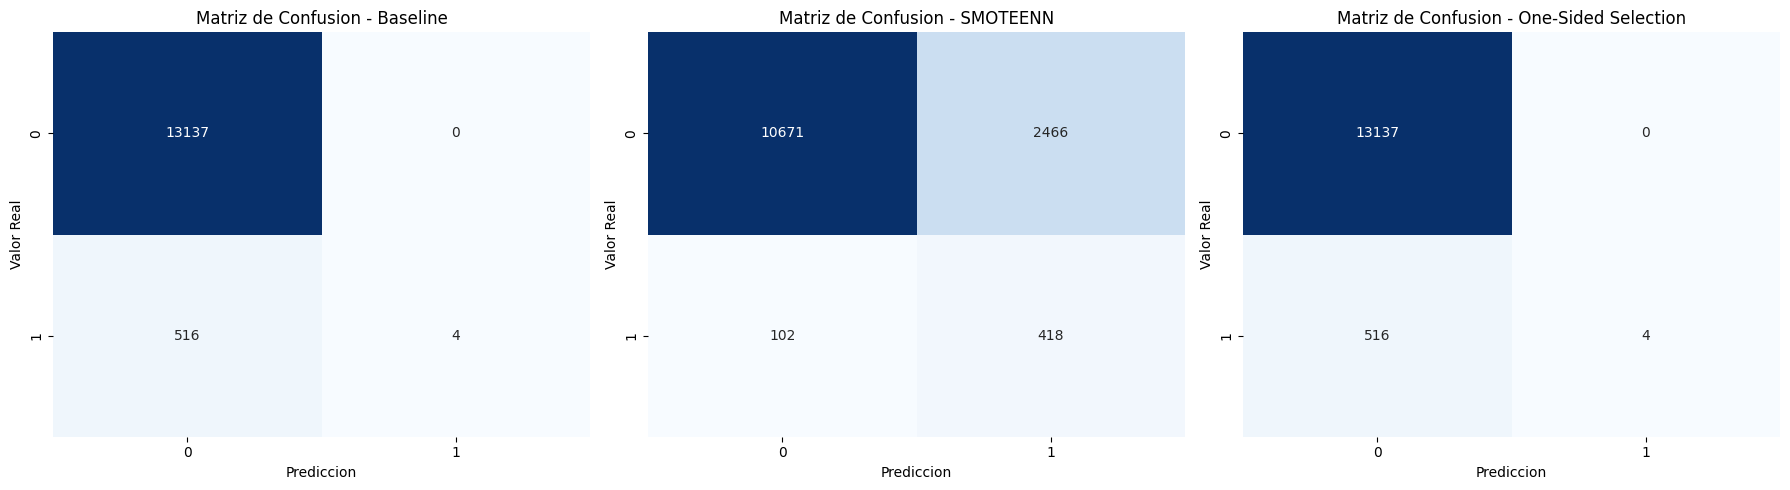

In [5]:
# Validación Cruzada Estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipelines = {'Baseline': baseline_pipeline,'SMOTEENN': smoteenn_pipeline,'One-Sided Selection': oss_pipeline}
resultados = []
matrices_confusion = {}

for nombre, pipeline in pipelines.items():
    print(f"Entrenando y evaluando: {nombre}...") #evaluacion que esta ocurriendo
    y_pred = cross_val_predict(pipeline, X, y, cv=cv)

    # 5. Evaluación de Resultados
    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, average='macro'),
        'Recall': recall_score(y, y_pred, average='macro'),
        'F1-Score': f1_score(y, y_pred, average='macro')})

    matrices_confusion[nombre] = confusion_matrix(y, y_pred)

df_resultados = pd.DataFrame(resultados)
display(df_resultados)
df_melted = df_resultados.melt(id_vars='Modelo', var_name='Metrica', value_name='Puntuacion')
sns.barplot(data=df_melted, x='Metrica', y='Puntuacion', hue='Modelo', palette='Set2')
plt.title('Comparativa de Métricas por Modelo', fontsize=15)
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

#grafica de matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (nombre, cm) in enumerate(matrices_confusion.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
    axes[i].set_title(f'Matriz de Confusion - {nombre}')
    axes[i].set_xlabel('Prediccion')
    axes[i].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()

El accuracy no es suficiente para evaluar el problema, es engañoso y no sirve para saber si un modelo es realmente útil ya que suele centrarse en los grupos mayores

6.Discusión y Conclusiones

Discutir:

El impacto del desbalance sobre el desempeño del modelo.

Las diferencias observadas entre SMOTEENN y One-Sided Selection.

Qué método produjo los mejores resultados y por qué.

## 6. Discusión y Conclusiones

### Análisis de Métricas: ¿Es el Accuracy suficiente?
En los resultados del modelo Baseline, el accuracy es engañosamente alta. Ya que el modelo esta aprendiendo a clasificar la mayoria de las instancias de la clase dominante, ignorando a la minoritaria. Por lo tanto, el accuracy no es suficiente para evaluar este tipo de problemas; dependemos de metricas como el F1-Score (Macro), que otorgan el mismo peso en ambas clases, penalizando al modelo si falla en la identificacion de los casos raros pero criticos.

### Diferencias entre SMOTEENN y One-Sided Selection (OSS)
- **One-Sided Selection (OSS)**  Elimino muestras que se consideraban redundantes en la clase mayoritaria, pero preservo la mayoria de los datos, manteniendo un desbalance evidente aunque mas limpio.
- **SMOTEENN** tuvo un impacto mucho mas drastico. No solo sobremuestreo la clase minoritaria creando datos sinteticos, sino que luego aplico limpieza eliminando instancias de ambas clases que generaban confusion en la frontera.

### Conclusión Tecnica

En las graficas obtenidas se muestra que tanto el modelo Base como el método One-Sided Selection obtienen una exactitud engañosamente alta (0.962) ya que ignoran casi por completo a la clase minoritaria, acertando apenas 4 de 520 casos criticos. Mientras que, SMOTEENN es la estrategia mas efectiva sacrificando un poco de exactitud global (bajando a 0.811), logra equilibrar el modelo y detecta exitosamente 418 casos de la clase minoritaria, obteniendo asi el mejor rendimiento para resolver el problema.